[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shahin1717/ai-roadmap/blob/main/math/linear-algebra/independence-basis-and-dimension/notebook.ipynb)

# Independence, Basis, and Dimension: hands-on

This notebook goes with the [topic README](README.md). You will test sets of vectors for independence, draw spans in 2D and 3D, find coordinates in a skewed basis, pull a basis out of a matrix, build the four fundamental subspaces of one matrix, and see why rank limits what a layer or a low-rank update can do. It uses NumPy, Matplotlib, `scipy.linalg`, and SymPy, and runs in a few seconds on a CPU.

Run the cells from top to bottom. After each demo, change a number and run it again.

In [1]:
%matplotlib inline
import numpy as np
import scipy.linalg as sla
import sympy as sp
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 70
plt.rcParams["axes.titlesize"] = 11
np.set_printoptions(precision=3, suppress=True)

## 1. Independence checker

Put the vectors in the **columns** of a matrix $A$. They are independent exactly when the only solution of $A\mathbf{x} = \mathbf{0}$ is $\mathbf{x} = \mathbf{0}$, that is, when the rank equals the number of columns. When they are dependent, the nullspace vector tells us **which combination** gives zero.

In [2]:
def check_independence(*vectors):
    """Report whether the given vectors are independent, and a relation if not."""
    A = np.column_stack(vectors).astype(float)
    r = np.linalg.matrix_rank(A)
    k = A.shape[1]
    if r == k:
        return f"independent (rank {r} = {k} vectors)"
    n = sla.null_space(A)[:, 0]
    n = n / n[np.argmax(np.abs(n) > 1e-9)]                  # scale so the first nonzero entry is 1
    terms = " + ".join(f"({c:.2g}) v{i + 1}" for i, c in enumerate(n))
    return f"DEPENDENT (rank {r} < {k} vectors): {terms} = 0"


tests = {
    "(1,0), (0,1)":                       [(1, 0), (0, 1)],
    "(1,2), (2,4)":                       [(1, 2), (2, 4)],
    "(1,0), (0,1), (5,7)  [3 in R^2]":    [(1, 0), (0, 1), (5, 7)],
    "(1,0,0), (0,1,0), (1,1,0)":          [(1, 0, 0), (0, 1, 0), (1, 1, 0)],
    "(1,2,1), (0,1,1), (1,3,2)":          [(1, 2, 1), (0, 1, 1), (1, 3, 2)],
    "(1,0,0), (0,1,0), (0,0,1)":          [(1, 0, 0), (0, 1, 0), (0, 0, 1)],
}
for name, vecs in tests.items():
    print(f"{name:36s} {check_independence(*vecs)}")

(1,0), (0,1)                         independent (rank 2 = 2 vectors)
(1,2), (2,4)                         DEPENDENT (rank 1 < 2 vectors): (1) v1 + (-0.5) v2 = 0
(1,0), (0,1), (5,7)  [3 in R^2]      DEPENDENT (rank 2 < 3 vectors): (1) v1 + (1.4) v2 + (-0.2) v3 = 0
(1,0,0), (0,1,0), (1,1,0)            DEPENDENT (rank 2 < 3 vectors): (1) v1 + (1) v2 + (-1) v3 = 0
(1,2,1), (0,1,1), (1,3,2)            DEPENDENT (rank 2 < 3 vectors): (1) v1 + (1) v2 + (-1) v3 = 0
(1,0,0), (0,1,0), (0,0,1)            independent (rank 3 = 3 vectors)


Notice the third line: **three vectors in $\mathbb{R}^2$ are always dependent**, because a $2 \times 3$ matrix has rank at most 2 and so must have a free column. Now a picture of spans. Two independent vectors in $\mathbb{R}^3$ span a plane. A third vector in that plane adds nothing (left panel). A third vector outside the plane makes the three vectors span all of space (right panel).

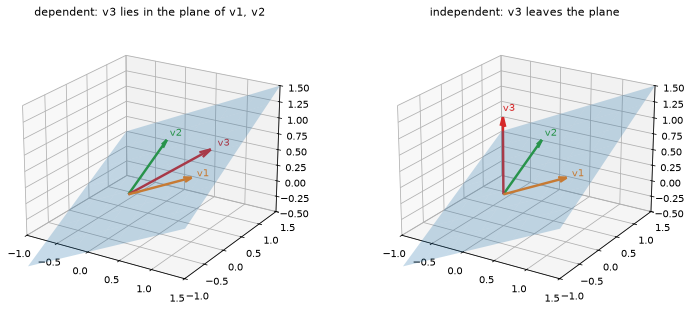

left : DEPENDENT (rank 2 < 3 vectors): (1) v1 + (0.5) v2 + (-1) v3 = 0
right: independent (rank 3 = 3 vectors)


In [3]:
v1, v2 = np.array([1.0, 0.0, 0.5]), np.array([0.0, 1.0, 0.5])
v3_in = v1 + 0.5 * v2                  # inside the plane of v1 and v2
v3_out = np.array([0.0, 0.0, 1.2])     # sticks out of that plane

s, t = np.meshgrid(np.linspace(-1, 1.5, 8), np.linspace(-1, 1.5, 8))
plane = s[..., None] * v1 + t[..., None] * v2

fig = plt.figure(figsize=(11, 4.6))
for k, (v3, title) in enumerate([(v3_in, "dependent: v3 lies in the plane of v1, v2"),
                                 (v3_out, "independent: v3 leaves the plane")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.plot_surface(plane[..., 0], plane[..., 1], plane[..., 2], alpha=0.25, color="C0")
    for v, color, name in [(v1, "C1", "v1"), (v2, "C2", "v2"), (v3, "C3", "v3")]:
        ax.quiver(0, 0, 0, *v, color=color, lw=2.5, arrow_length_ratio=0.12)
        ax.text(*(v * 1.08), name, color=color)
    ax.set_xlim(-1, 1.5); ax.set_ylim(-1, 1.5); ax.set_zlim(-0.5, 1.5)
    ax.view_init(elev=22, azim=-58)
    ax.set_title(title)
plt.tight_layout()
plt.show()
print("left :", check_independence(v1, v2, v3_in))
print("right:", check_independence(v1, v2, v3_out))

## 2. Coordinates in a basis

A **basis** is a set of independent vectors that spans the space. Every vector then has exactly one set of **coordinates**: the combination of basis vectors that builds it. Take the basis $\mathbf{b}_1 = (2, 1)$ and $\mathbf{b}_2 = (1, 2)$ and the vector $\mathbf{v} = (4, 5)$. Putting the basis vectors in the columns of $B$, the coordinates $\mathbf{c}$ solve $B\mathbf{c} = \mathbf{v}$.

coordinates c = [1. 2.] -> c1*b1 + c2*b2 = [4. 5.]


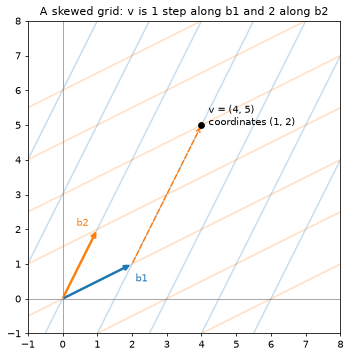

In [4]:
b1, b2 = np.array([2, 1]), np.array([1, 2])
B = np.column_stack([b1, b2])
v = np.array([4, 5])

c = np.linalg.solve(B, v)
print("coordinates c =", c, "-> c1*b1 + c2*b2 =", c[0] * b1 + c[1] * b2)

fig, ax = plt.subplots(figsize=(5.8, 5.8))
for k in range(-3, 5):                                   # the skewed grid made by the basis
    ax.plot(*np.array([k * b1 - 4 * b2, k * b1 + 5 * b2]).T, color="C0", alpha=0.25)
    ax.plot(*np.array([-4 * b1 + k * b2, 5 * b1 + k * b2]).T, color="C1", alpha=0.25)
ax.annotate("", xy=b1, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C0", lw=2.5))
ax.annotate("", xy=b2, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C1", lw=2.5))
ax.annotate("", xy=c[0] * b1, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="C0", lw=1.5, ls="--"))
ax.annotate("", xy=v, xytext=c[0] * b1, arrowprops=dict(arrowstyle="->", color="C1", lw=1.5, ls="--"))
ax.scatter(*v, color="k", zorder=5)
ax.text(v[0] + 0.2, v[1], "v = (4, 5)\ncoordinates (1, 2)")
ax.text(*(b1 + [0.1, -0.5]), "b1", color="C0"); ax.text(*(b2 + [-0.6, 0.1]), "b2", color="C1")
ax.set_xlim(-1, 8); ax.set_ylim(-1, 8); ax.set_aspect("equal")
ax.axhline(0, color="gray", lw=0.7); ax.axvline(0, color="gray", lw=0.7)
ax.set_title("A skewed grid: v is 1 step along b1 and 2 along b2")
plt.show()

The same point has the standard coordinates $(4, 5)$ and the new coordinates $(1, 2)$. Only the grid changed. If $B$ had dependent columns it could not be inverted, and some vectors would have no coordinates at all or many different ones.

## 3. A basis from the pivot columns

To find a basis for a column space, row reduce and keep the **columns of the original matrix** that sit in the pivot positions. We write the reduction freshly here and let it report the pivots. The free columns of $R$ also show **how** each dependent column is built from the pivot ones.

In [5]:
def reduce_to_rref(A, tol=1e-12):
    """Return the reduced row echelon form R and the pivot column indices."""
    R = np.array(A, dtype=float)
    rows, cols = R.shape
    pivots = []
    r = 0
    for c in range(cols):
        if r == rows:
            break
        candidates = np.nonzero(np.abs(R[r:, c]) > tol)[0]
        if len(candidates) == 0:
            continue
        p = r + candidates[0]
        R[[r, p]] = R[[p, r]]
        R[r] /= R[r, c]
        for i in range(rows):
            if i != r:
                R[i] -= R[i, c] * R[r]
        pivots.append(c)
        r += 1
    return R, pivots


# four vectors in R^3, as columns
V = np.array([[1, 2, 0, 1],
              [2, 4, 1, 3],
              [1, 2, 1, 2]])
R, pivots = reduce_to_rref(V)
print("R =\n", R + 0.0)
print("pivot columns (counting from 1):", [p + 1 for p in pivots])
basis = V[:, pivots]
print("basis for the span (columns of the ORIGINAL matrix):\n", basis)
print("dimension of the span =", len(pivots))

R =
 [[1. 2. 0. 1.]
 [0. 0. 1. 1.]
 [0. 0. 0. 0.]]
pivot columns (counting from 1): [1, 3]
basis for the span (columns of the ORIGINAL matrix):
 [[1 0]
 [2 1]
 [1 1]]
dimension of the span = 2


In [6]:
# The free columns of R give the recipes for the dependent vectors
print("column 2 = 2 * column 1        :", np.allclose(V[:, 1], 2 * V[:, 0]))
print("column 4 = column 1 + column 3 :", np.allclose(V[:, 3], V[:, 0] + V[:, 2]))

sympy_R, sympy_pivots = sp.Matrix(V).rref()
print("SymPy agrees on R and pivots   :", np.allclose(R, np.array(sympy_R.tolist(), dtype=float)), list(sympy_pivots) == pivots)

column 2 = 2 * column 1        : True
column 4 = column 1 + column 3 : True
SymPy agrees on R and pivots   : True True


## 4. The four fundamental subspaces

For an $m \times n$ matrix of rank $r$ there are four subspaces with dimensions $r$, $n - r$, $r$, and $m - r$. Here is a $4 \times 5$ matrix of rank 3. We compute a basis for each subspace and check the dimensions and the right-angle relations.

In [7]:
r1 = np.array([1, 2, 0, 1, 2])
r2 = np.array([0, 0, 1, 1, 1])
r3 = np.array([0, 0, 0, 0, 1])
A = np.array([r1, r2, r3, r1 + r2])          # the fourth row is the sum of the first two
m, n = A.shape
r = np.linalg.matrix_rank(A)

col_space = sla.orth(A)                      # basis for C(A), a subspace of R^m
null_space = sla.null_space(A)               # basis for N(A), a subspace of R^n
row_space = sla.orth(A.T)                    # basis for the row space, a subspace of R^n
left_null = sla.null_space(A.T)              # basis for the left nullspace, a subspace of R^m

print(f"A is {m} x {n} with rank r = {r}")
print(f"column space   in R^{m}: dimension {col_space.shape[1]}   (r = {r})")
print(f"nullspace      in R^{n}: dimension {null_space.shape[1]}   (n - r = {n - r})")
print(f"row space      in R^{n}: dimension {row_space.shape[1]}   (r = {r})")
print(f"left nullspace in R^{m}: dimension {left_null.shape[1]}   (m - r = {m - r})")

print("\nrow space is perpendicular to the nullspace    :", np.allclose(row_space.T @ null_space, 0))
print("column space is perpendicular to left nullspace:", np.allclose(col_space.T @ left_null, 0))

y = left_null[:, 0] / left_null[0, 0]
print("a left nullspace vector (scaled):", np.round(y, 3), "-> y @ A =", np.round(y @ A, 6))

A is 4 x 5 with rank r = 3
column space   in R^4: dimension 3   (r = 3)
nullspace      in R^5: dimension 2   (n - r = 2)
row space      in R^5: dimension 3   (r = 3)
left nullspace in R^4: dimension 1   (m - r = 1)

row space is perpendicular to the nullspace    : True
column space is perpendicular to left nullspace: True
a left nullspace vector (scaled): [ 1.  1. -0. -1.] -> y @ A = [ 0.  0. -0. -0.  0.]


The left nullspace vector tells us the combination of **rows** that cancels: row 1 plus row 2 minus row 4 equals zero, exactly how $A$ was built. Next, the rank-nullity count $r + (n - r) = n$ on many random matrices of different shapes and ranks.

In [8]:
rng = np.random.default_rng(0)
ok = 0
trials = 300
for _ in range(trials):
    m = int(rng.integers(2, 9))
    n = int(rng.integers(2, 9))
    k = int(rng.integers(1, min(m, n) + 1))          # build a matrix of rank (at most) k
    A = rng.normal(size=(m, k)) @ rng.normal(size=(k, n))
    r = np.linalg.matrix_rank(A)
    nullity = sla.null_space(A).shape[1]
    left_nullity = sla.null_space(A.T).shape[1]
    ok += (r + nullity == n) and (r + left_nullity == m)
print(f"r + (n - r) = n and r + (m - r) = m held for {ok} of {trials} random matrices")

r + (n - r) = n and r + (m - r) = m held for 300 of 300 random matrices


## 5. Rank of a product, and a bottleneck layer

The columns of $AB$ are combinations of the columns of $A$, so the rank of a product can never exceed the rank of either factor: $\text{rank}(AB) \le \min(\text{rank } A, \text{rank } B)$. In a network, a **bottleneck** (a narrow hidden layer) caps the rank of the whole linear map. Below, a 10-input network squeezes through 2 hidden values and expands again to 10 outputs.

In [9]:
rng = np.random.default_rng(1)
W1 = rng.normal(size=(2, 10))        # 10 inputs -> 2 hidden values (the bottleneck)
W2 = rng.normal(size=(10, 2))        # 2 hidden values -> 10 outputs
W = W2 @ W1                          # the whole linear network as one 10 x 10 matrix

print("W has shape", W.shape, "but rank", np.linalg.matrix_rank(W))
X = rng.normal(size=(10, 50))        # 50 random inputs, one per column
Y = W @ X
print("rank of the 50 outputs together:", np.linalg.matrix_rank(Y), "(they all lie in a 2-dimensional subspace)")

# the inequality on random products
violations = 0
for _ in range(300):
    A = rng.normal(size=(6, 4)) @ rng.normal(size=(4, 6))     # rank at most 4
    B = rng.normal(size=(6, 3)) @ rng.normal(size=(3, 6))     # rank at most 3
    violations += np.linalg.matrix_rank(A @ B) > min(np.linalg.matrix_rank(A), np.linalg.matrix_rank(B))
print("rank(AB) > min(rank A, rank B) happened", violations, "times in 300 trials")

W has shape (10, 10) but rank 2
rank of the 50 outputs together: 2 (they all lie in a 2-dimensional subspace)
rank(AB) > min(rank A, rank B) happened 0 times in 300 trials


## 6. Low-rank factorization: fewer numbers

A matrix of rank $r$ can be written as $W = BA$ with $B$ of size $d \times r$ and $A$ of size $r \times k$. Storing $B$ and $A$ takes $r(d + k)$ numbers instead of $dk$. Low-rank adapters (LoRA) use this idea to change a large weight matrix $W_0$ by adding a low-rank piece, $W_0 + BA$, so that only the small matrices need training.

In [10]:
d = k = 256
r = 4
rng = np.random.default_rng(2)
B = rng.normal(size=(d, r))
A = rng.normal(size=(r, k))
W = B @ A

print("W has shape", W.shape, "and rank", np.linalg.matrix_rank(W))
print("numbers in W itself      :", W.size)
print("numbers in B and A       :", B.size + A.size)
print(f"saving factor            : {W.size / (B.size + A.size):.0f}x")

x = rng.normal(size=k)
print("W x equals B (A x)       :", np.allclose(W @ x, B @ (A @ x)))

# LoRA-style update: a full matrix W0 plus a rank-4 change
W0 = rng.normal(size=(d, k))
W_new = W0 + B @ A
print("rank of W0              :", np.linalg.matrix_rank(W0))
print("rank of the change B A  :", np.linalg.matrix_rank(B @ A))

W has shape (256, 256) and rank 4
numbers in W itself      : 65536
numbers in B and A       : 2048
saving factor            : 32x
W x equals B (A x)       : True
rank of W0              : 256
rank of the change B A  : 4


## 7. Nearly dependent columns

Real data is rarely exactly dependent, so the rank depends on a **tolerance**: how small a number counts as zero. Below, the third column is the sum of the first two plus a tiny change.

In [11]:
X = np.array([[1, 2, 3],
              [2, 0, 2],
              [0, 1, 1],
              [3, 1, 4.]])                   # the third column is column 1 + column 2
X_near = X.copy()
X_near[:, 2] += 1e-6 * np.array([1, -1, 1, 0])

print("rank of X                    :", np.linalg.matrix_rank(X))
print("rank of X_near (default tol) :", np.linalg.matrix_rank(X_near))
print("rank of X_near (tol = 1e-4)  :", np.linalg.matrix_rank(X_near, tol=1e-4))
print(f"condition number of X_near^T X_near: {np.linalg.cond(X_near.T @ X_near):.1e}")

rank of X                    : 2
rank of X_near (default tol) : 3
rank of X_near (tol = 1e-4)  : 2
condition number of X_near^T X_near: 5.4e+14


The condition number is a warning light: a huge value means that solving with this matrix can magnify tiny errors enormously. Depending on rounding, such a solve may raise an error, or it may return absurdly large or arbitrary-looking numbers without any error at all. Check the rank and the condition number first.

## Recap and next steps

* Vectors are **independent** when only the zero combination gives zero: the matrix with those columns has rank equal to the number of columns, and its nullspace is $\{\mathbf{0}\}$.
* A **basis** is independent and spanning, and gives every vector exactly one set of coordinates. The **dimension** is the number of vectors in any basis.
* A basis for $C(A)$ is the set of pivot columns of $A$. The four fundamental subspaces have dimensions $r$, $n - r$, $r$, $m - r$, and rank-nullity says $r + (n - r) = n$.
* The row space is perpendicular to the nullspace, and the column space to the left nullspace (the full story comes in the orthogonality topic).
* $\text{rank}(AB) \le \min(\text{rank } A, \text{rank } B)$, so bottlenecks limit what a linear network can do, and low-rank factors store a matrix with far fewer numbers.

**Try it yourself:** in section 1, add a fourth vector to the 3D example and predict the rank before you compute it. Then do the [exercises](exercises/problems.md) and the [assignment](assignment.md).

Next topic: [Orthogonality and Gram-Schmidt](../orthogonality-and-gram-schmidt/README.md).